In [1]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd

# Xác định thư mục gốc project
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Tạo các thư mục cần thiết nếu chưa tồn tại
(PROJECT_ROOT / "agents").mkdir(exist_ok=True)
(PROJECT_ROOT / "training").mkdir(exist_ok=True)
(PROJECT_ROOT / "models").mkdir(exist_ok=True)
(PROJECT_ROOT / "results").mkdir(exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Project: D:\TTNTNC\TicTacToe_AI
Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
NumPy: 2.4.6
Pandas: 3.1.1


In [2]:
try:
    import torch
    import torch.nn as nn
    import torch.optim as optim

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

except ImportError:
    print("Chưa cài đặt PyTorch!")

PyTorch: 2.15.0+cu132
CUDA available: True
Device: CUDA


In [3]:
import torch
import torch.nn as nn

# Neural Network thử nghiệm
model = nn.Sequential(
    nn.Linear(16, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 16)
)

# Bàn cờ thử nghiệm
sample_state = torch.zeros(1, 16)

# Dự đoán Q-values
q_values = model(sample_state)

print("Input shape:", sample_state.shape)
print("Output shape:", q_values.shape)
print("Q-values:", q_values)

Input shape: torch.Size([1, 16])
Output shape: torch.Size([1, 16])
Q-values: tensor([[ 0.0004,  0.0485, -0.0447,  0.0854, -0.1055, -0.0493, -0.0309,  0.1280,
         -0.0540,  0.0444,  0.0177,  0.0611,  0.0120,  0.1275,  0.0312, -0.0020]],
       grad_fn=<AddmmBackward0>)


In [4]:
import numpy as np
import torch

def encode_state(board, player):
    """
    Chuyển bàn cờ thành vector 16 phần tử
    theo góc nhìn của người chơi hiện tại.

    1  : Quân của bản thân
    -1 : Quân đối thủ
    0  : Ô trống
    """

    board = np.array(board)

    state = board.flatten() * player

    return state.astype(np.float32)

In [5]:
sample_board = np.array([
    [ 1,  0, -1,  0],
    [ 0,  1,  0,  0],
    [-1,  0,  1,  0],
    [ 0,  0,  0, -1]
])

state_x = encode_state(sample_board, player=1)
state_o = encode_state(sample_board, player=-1)

print("State X:", state_x)
print("State O:", state_o)
print("State shape:", state_x.shape)

State X: [ 1.  0. -1.  0.  0.  1.  0.  0. -1.  0.  1.  0.  0.  0.  0. -1.]
State O: [-1.  0.  1.  0.  0. -1.  0.  0.  1.  0. -1.  0.  0.  0.  0.  1.]
State shape: (16,)


In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from agents.dqn_network import DQNNetwork

model = DQNNetwork()

sample_state = torch.tensor(
    encode_state(sample_board, player=1)
).unsqueeze(0)

q_values = model(sample_state)

print("Input:", sample_state.shape)
print("Output:", q_values.shape)
print("Number of parameters:",
      sum(p.numel() for p in model.parameters()))

Input: torch.Size([1, 16])
Output: torch.Size([1, 16])
Number of parameters: 20752


In [7]:
from agents.replay_buffer import ReplayBuffer
import numpy as np

buffer = ReplayBuffer(capacity=1000)

for i in range(100):
    state = np.random.randn(16).astype(np.float32)
    action = np.random.randint(0, 16)
    reward = np.random.choice([-1, 0, 1])
    next_state = np.random.randn(16).astype(np.float32)
    done = (i % 10 == 0)

    buffer.push(state, action, reward, next_state, done)

print("Buffer size:", len(buffer))

batch = buffer.sample(32)

print("States:", batch[0].shape)
print("Actions:", batch[1].shape)
print("Rewards:", batch[2].shape)
print("Next states:", batch[3].shape)
print("Dones:", batch[4].shape)

Buffer size: 100
States: (32, 16)
Actions: (32,)
Rewards: (32,)
Next states: (32, 16)
Dones: (32,)


In [8]:
from agents.dqn_agent import DQNAgent
from agents.dqn_network import DQNNetwork
from agents.replay_buffer import ReplayBuffer

agent = DQNAgent()

print("Device:", agent.device)
print("Epsilon:", agent.epsilon)
print("Policy Network:", type(agent.policy_net).__name__)
print("Target Network:", type(agent.target_net).__name__)
print("Replay Buffer:", len(agent.memory))

print(
    "Networks initially identical:",
    all(
        torch.equal(p1, p2)
        for p1, p2 in zip(
            agent.policy_net.parameters(),
            agent.target_net.parameters()
        )
    )
)

Device: cuda
Epsilon: 1.0
Policy Network: DQNNetwork
Target Network: DQNNetwork
Replay Buffer: 0
Networks initially identical: True


In [9]:
import torch

device = torch.device("cuda")

x = torch.randn(3000, 3000, device=device)
y = torch.randn(3000, 3000, device=device)

z = torch.matmul(x, y)

print("Device:", z.device)
print("Shape:", z.shape)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda:0
Shape: torch.Size([3000, 3000])
GPU: NVIDIA GeForce RTX 5070


In [10]:
agent = DQNAgent()
print("DQN Device:", agent.device)

DQN Device: cuda


In [11]:
from agents.dqn_agent import DQNAgent
from agents.dqn_network import DQNNetwork
from agents.replay_buffer import ReplayBuffer

agent = DQNAgent()

print("Device:", agent.device)
print("Epsilon:", agent.epsilon)
print("Policy Network:", type(agent.policy_net).__name__)
print("Target Network:", type(agent.target_net).__name__)
print("Replay Buffer:", len(agent.memory))

print(
    "Networks initially identical:",
    all(
        torch.equal(p1, p2)
        for p1, p2 in zip(
            agent.policy_net.parameters(),
            agent.target_net.parameters()
        )
    )
)

Device: cuda
Epsilon: 1.0
Policy Network: DQNNetwork
Target Network: DQNNetwork
Replay Buffer: 0
Networks initially identical: True


In [12]:
import torch

device = torch.device("cuda")

x = torch.randn(3000, 3000, device=device)
y = torch.randn(3000, 3000, device=device)

z = torch.matmul(x, y)

torch.cuda.synchronize()

print("Device:", z.device)
print("Shape:", z.shape)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

Device: cuda:0
Shape: torch.Size([3000, 3000])
GPU: NVIDIA GeForce RTX 5070
GPU memory allocated: 103.16 MB


In [13]:
def action_to_index(action):
    row, col = action
    return row * 4 + col


def index_to_action(index):
    return (index // 4, index % 4)

In [14]:
from game.game_engine import GameEngine
from agents.random_agent import RandomAgent
from agents.dqn_agent import DQNAgent
from agents.dqn_network import DQNNetwork
from agents.replay_buffer import ReplayBuffer

import numpy as np
import random
import torch

In [15]:
def action_to_index(action):
    row, col = action
    return row * 4 + col


def index_to_action(index):
    return (index // 4, index % 4)

In [16]:
def get_dqn_winner(board, win_length=4):
    board = np.asarray(board)
    size = board.shape[0]

    directions = [
        (0, 1),   # Ngang
        (1, 0),   # Dọc
        (1, 1),   # Chéo xuống
        (1, -1)   # Chéo lên
    ]

    for r in range(size):
        for c in range(size):
            player = board[r, c]

            if player == 0:
                continue

            for dr, dc in directions:
                end_r = r + (win_length - 1) * dr
                end_c = c + (win_length - 1) * dc

                if not (
                    0 <= end_r < size and
                    0 <= end_c < size
                ):
                    continue

                cells = [
                    board[r + i * dr, c + i * dc]
                    for i in range(win_length)
                ]

                if all(cell == player for cell in cells):
                    return int(player)

    return None

In [17]:
def play_dqn_episode(dqn_agent, dqn_player=1, training=True):
    game = GameEngine()
    random_agent = RandomAgent()

    if dqn_player not in [1, -1]:
        raise ValueError("dqn_player phải là 1 hoặc -1")

    episode_reward = 0

    while not game.is_terminal():

        current_player = game.state.current_player

        # Đến lượt DQN
        if current_player == dqn_player:

            state = encode_state(
                game.state.board,
                dqn_player
            )

            legal_actions = game.legal_actions()

            legal_indices = [
                action_to_index(action)
                for action in legal_actions
            ]

            action_index = dqn_agent.choose_action(
                state,
                legal_indices,
                training=training
            )

            action = index_to_action(action_index)

            if action not in legal_actions:
                raise ValueError(
                    f"DQN chọn nước đi không hợp lệ: {action}"
                )

            game.step(action)

            # DQN thắng ngay sau nước đi
            if game.is_terminal():

                winner = get_dqn_winner(
                    game.state.board,
                    game.win_length
                )

                reward = (
                    1.0 if winner == dqn_player
                    else 0.0
                )

                next_state = encode_state(
                    game.state.board,
                    dqn_player
                )

                if training:
                    dqn_agent.remember(
                        state,
                        action_index,
                        reward,
                        next_state,
                        True
                    )

                episode_reward += reward
                break

            # Random Agent phản công
            opponent_action = random_agent.choose_action(game)
            game.step(opponent_action)

            # Xác định kết quả sau lượt của Random
            if game.is_terminal():

                winner = get_dqn_winner(
                    game.state.board,
                    game.win_length
                )

                if winner == dqn_player:
                    reward = 1.0
                elif winner == -dqn_player:
                    reward = -1.0
                else:
                    reward = 0.0

                done = True

            else:
                reward = 0.0
                done = False

            next_state = encode_state(
                game.state.board,
                dqn_player
            )

            if training:
                dqn_agent.remember(
                    state,
                    action_index,
                    reward,
                    next_state,
                    done
                )

                dqn_agent.train_step()

            episode_reward += reward

        # Random đi trước khi DQN chơi O
        else:
            action = random_agent.choose_action(game)
            game.step(action)

    winner = get_dqn_winner(
        game.state.board,
        game.win_length
    )

    if winner == dqn_player:
        result = "Win"
    elif winner == -dqn_player:
        result = "Loss"
    else:
        result = "Draw"

    return {
        "result": result,
        "reward": episode_reward,
        "winner": winner
    }

In [18]:
dqn_test = DQNAgent()

test_result = play_dqn_episode(
    dqn_agent=dqn_test,
    dqn_player=1,
    training=True
)

print("===== DQN EPISODE TEST =====")
print("Result:", test_result["result"])
print("Reward:", test_result["reward"])
print("Winner:", test_result["winner"])
print("Replay Buffer:", len(dqn_test.memory))
print("Epsilon:", dqn_test.epsilon)

===== DQN EPISODE TEST =====
Result: Draw
Reward: 0.0
Winner: None
Replay Buffer: 8
Epsilon: 1.0


In [19]:
test_result_o = play_dqn_episode(
    dqn_agent=dqn_test,
    dqn_player=-1,
    training=True
)

print("===== DQN AS PLAYER O =====")
print("Result:", test_result_o["result"])
print("Reward:", test_result_o["reward"])
print("Winner:", test_result_o["winner"])
print("Replay Buffer:", len(dqn_test.memory))

===== DQN AS PLAYER O =====
Result: Loss
Reward: -1.0
Winner: 1
Replay Buffer: 14


In [31]:
import importlib
import agents.dqn_agent

importlib.reload(agents.dqn_agent)

from agents.dqn_agent import DQNAgent

print("Đã cập nhật DQN Agent!")


Đã cập nhật DQN Agent!


In [32]:


dqn_agent = DQNAgent(
    state_size=16,
    action_size=16,
    learning_rate=0.001,
    gamma=0.99,
    epsilon=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.995,
    buffer_capacity=10000,
    batch_size=64
)

print("Device:", dqn_agent.device)
print("Epsilon:", dqn_agent.epsilon)



Device: cuda
Epsilon: 1.0


In [33]:

import pandas as pd
import time

def train_dqn(agent, episodes=3000, target_update_interval=10):
    history = []

    start_time = time.time()

    for episode in range(1, episodes + 1):

        # Đổi vai X/O luân phiên để tránh thiên lệch
        dqn_player = 1 if episode % 2 == 1 else -1

        result = play_dqn_episode(
            dqn_agent=agent,
            dqn_player=dqn_player,
            training=True
        )

        # Giảm epsilon sau mỗi ván
        agent.decay_epsilon()

        # Đồng bộ Target Network định kỳ
        if episode % target_update_interval == 0:
            agent.update_target_network()

        history.append({
            "episode": episode,
            "result": result["result"],
            "reward": result["reward"],
            "epsilon": agent.epsilon
        })

        # In tiến độ mỗi 100 ván
        if episode % 100 == 0:
            recent = history[-100:]

            wins = sum(x["result"] == "Win" for x in recent)
            draws = sum(x["result"] == "Draw" for x in recent)
            losses = sum(x["result"] == "Loss" for x in recent)

            print(
                f"Episode {episode}/{episodes} | "
                f"Win: {wins}% | Draw: {draws}% | "
                f"Loss: {losses}% | "
                f"Epsilon: {agent.epsilon:.3f}"
            )

    elapsed = time.time() - start_time

    print("\nHOÀN THÀNH HUẤN LUYỆN")
    print(f"Số ván: {episodes}")
    print(f"Thời gian: {elapsed:.2f} giây")
    print(f"Epsilon cuối: {agent.epsilon:.3f}")

    return pd.DataFrame(history)


In [34]:

training_history = train_dqn(
    agent=dqn_agent,
    episodes=3000,
    target_update_interval=10
)

training_history.head()


Episode 100/3000 | Win: 27% | Draw: 45% | Loss: 28% | Epsilon: 0.606
Episode 200/3000 | Win: 35% | Draw: 38% | Loss: 27% | Epsilon: 0.367
Episode 300/3000 | Win: 40% | Draw: 32% | Loss: 28% | Epsilon: 0.222
Episode 400/3000 | Win: 50% | Draw: 29% | Loss: 21% | Epsilon: 0.135
Episode 500/3000 | Win: 56% | Draw: 19% | Loss: 25% | Epsilon: 0.082
Episode 600/3000 | Win: 59% | Draw: 20% | Loss: 21% | Epsilon: 0.050
Episode 700/3000 | Win: 50% | Draw: 35% | Loss: 15% | Epsilon: 0.050
Episode 800/3000 | Win: 69% | Draw: 24% | Loss: 7% | Epsilon: 0.050
Episode 900/3000 | Win: 62% | Draw: 21% | Loss: 17% | Epsilon: 0.050
Episode 1000/3000 | Win: 57% | Draw: 24% | Loss: 19% | Epsilon: 0.050
Episode 1100/3000 | Win: 69% | Draw: 20% | Loss: 11% | Epsilon: 0.050
Episode 1200/3000 | Win: 67% | Draw: 17% | Loss: 16% | Epsilon: 0.050
Episode 1300/3000 | Win: 61% | Draw: 21% | Loss: 18% | Epsilon: 0.050
Episode 1400/3000 | Win: 59% | Draw: 24% | Loss: 17% | Epsilon: 0.050
Episode 1500/3000 | Win: 62% |

,episode,result,reward,epsilon
0,1,Draw,0.0,0.995000
1,2,Draw,0.0,0.990025
2,3,Loss,-1.0,0.985075
3,4,Win,1.0,0.980150
4,5,Win,1.0,0.975249


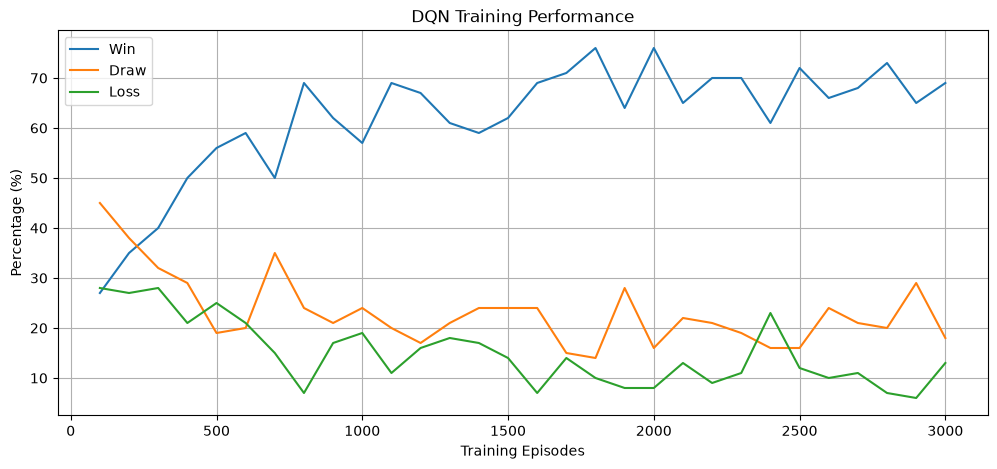

In [35]:

import matplotlib.pyplot as plt

# Tỷ lệ thắng, hòa, thua theo từng nhóm 100 ván
window = 100
results = []

for start in range(0, len(training_history), window):
    group = training_history.iloc[start:start + window]

    results.append({
        "episode": start + len(group),
        "Win": (group["result"] == "Win").mean() * 100,
        "Draw": (group["result"] == "Draw").mean() * 100,
        "Loss": (group["result"] == "Loss").mean() * 100
    })

result_df = pd.DataFrame(results)

plt.figure(figsize=(12, 5))
plt.plot(result_df["episode"], result_df["Win"], label="Win")
plt.plot(result_df["episode"], result_df["Draw"], label="Draw")
plt.plot(result_df["episode"], result_df["Loss"], label="Loss")

plt.xlabel("Training Episodes")
plt.ylabel("Percentage (%)")
plt.title("DQN Training Performance")
plt.legend()
plt.grid(True)
plt.show()


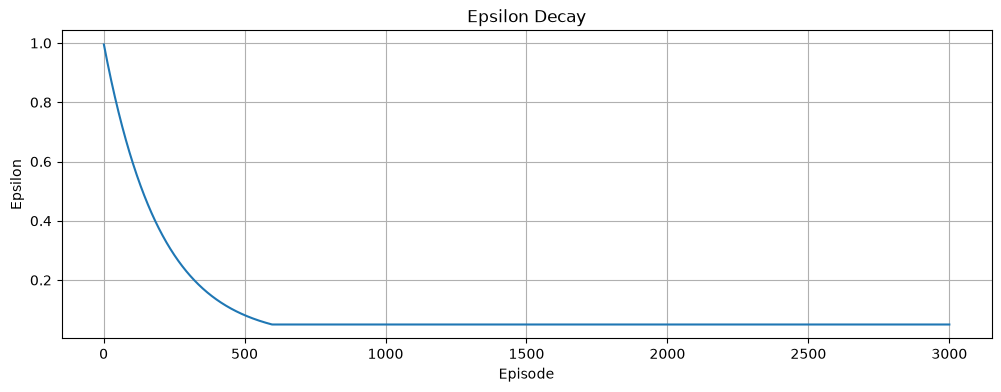

In [36]:

plt.figure(figsize=(12, 4))

plt.plot(
    training_history["episode"],
    training_history["epsilon"]
)

plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon Decay")
plt.grid(True)
plt.show()


In [37]:

def evaluate_dqn(agent, games=100):
    results = {"Win": 0, "Draw": 0, "Loss": 0}

    for i in range(games):
        dqn_player = 1 if i % 2 == 0 else -1

        result = play_dqn_episode(
            dqn_agent=agent,
            dqn_player=dqn_player,
            training=False
        )

        results[result["result"]] += 1

    print("KẾT QUẢ ĐÁNH GIÁ DQN")
    print("----------------------")

    for name, count in results.items():
        percentage = count / games * 100
        print(f"{name}: {count}/{games} ({percentage:.1f}%)")

    return results


evaluation_results = evaluate_dqn(
    agent=dqn_agent,
    games=100
)


KẾT QUẢ ĐÁNH GIÁ DQN
----------------------
Win: 66/100 (66.0%)
Draw: 17/100 (17.0%)
Loss: 17/100 (17.0%)


In [38]:

import os
import torch

# Tạo thư mục lưu mô hình
os.makedirs("../models", exist_ok=True)

# Lưu trọng số Policy Network
torch.save(
    dqn_agent.policy_net.state_dict(),
    "../models/dqn_tictactoe.pth"
)

# Lưu lịch sử huấn luyện
training_history.to_csv(
    "../models/dqn_training_history.csv",
    index=False
)

# Lưu kết quả đánh giá
pd.DataFrame([evaluation_results]).to_csv(
    "../models/dqn_evaluation.csv",
    index=False
)

print("Đã lưu mô hình DQN và dữ liệu huấn luyện!")


Đã lưu mô hình DQN và dữ liệu huấn luyện!


In [39]:

import inspect
import os
import sys

# Đảm bảo Python nhận diện thư mục gốc dự án
PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Import các Agent
from agents.random_agent import RandomAgent
from agents.heuristic_agent import HeuristicAgent
from agents.minimax_agent import MinimaxAgent
from agents.alphabeta_agent import AlphaBetaAgent
from agents.mcts_agent import MCTSAgent
from agents.dqn_agent import DQNAgent

agents = [
    RandomAgent,
    HeuristicAgent,
    MinimaxAgent,
    AlphaBetaAgent,
    MCTSAgent,
    DQNAgent
]

print("=" * 60)
print("KIỂM TRA API CỦA CÁC AI AGENT")
print("=" * 60)

for agent_class in agents:
    print(f"\nAgent: {agent_class.__name__}")

    # Kiểm tra hàm khởi tạo
    print("Constructor:", inspect.signature(agent_class.__init__))

    # Kiểm tra các phương thức
    for name, method in inspect.getmembers(
        agent_class,
        predicate=inspect.isfunction
    ):
        if not name.startswith("__"):
            print(f"  {name}{inspect.signature(method)}")


KIỂM TRA API CỦA CÁC AI AGENT

Agent: RandomAgent
Constructor: (self, name='Random Agent')
  choose_action(self, game)

Agent: HeuristicAgent
Constructor: (self, name='Heuristic Agent')
  choose_action(self, game)
  evaluate_board(self, board, player, segments)
  get_segments(self, board_size, win_length)
  is_winning_move(self, board, action, player, segments)

Agent: MinimaxAgent
Constructor: (self, depth=4, name='Minimax Agent')
  choose_action(self, game)
  evaluate_board(self, board, player, segments)
  get_segments(self, board_size, win_length)
  get_winner(self, board, segments)
  is_board_full(self, board)
  minimax(self, board, depth, maximizing, player, segments, board_size)
  order_actions(self, actions, board_size)

Agent: AlphaBetaAgent
Constructor: (self, depth=4, name='Alpha-Beta Agent')
  choose_action(self, game)
  evaluate_board(self, board, player, segments)
  get_segments(self, board_size, win_length)
  get_winner(self, board, segments)
  is_board_full(self, board)


In [40]:

from game.game_engine import GameEngine

print("=" * 60)
print("KIỂM TRA GAME ENGINE")
print("=" * 60)

print("Constructor:", inspect.signature(GameEngine.__init__))

for name, method in inspect.getmembers(
    GameEngine,
    predicate=inspect.isfunction
):
    if not name.startswith("__"):
        print(f"{name}{inspect.signature(method)}")


KIỂM TRA GAME ENGINE
Constructor: (self, board_size=4, win_length=4)
clone(self)
get_current_player(self)
get_state(self)
is_terminal(self)
legal_actions(self)
render(self)
reset(self)
result(self)
step(self, action)
undo(self)


In [41]:

import os

model_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "dqn_tictactoe.pth"
)

if os.path.exists(model_path):
    print("DQN Model: FOUND")
    print("Path:", model_path)
    print("Size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("DQN Model: NOT FOUND")
    print("Hãy kiểm tra lại thư mục models.")


DQN Model: FOUND
Path: D:\TTNTNC\TicTacToe_AI\models\dqn_tictactoe.pth
Size: 84.22 KB


In [42]:

from game.game_engine import GameEngine

game = GameEngine(board_size=4, win_length=4)

print("=" * 50)
print("KIỂM TRA GAME STATE")
print("=" * 50)

print("\n1. get_state():")
state = game.get_state()
print(state)
print("Kiểu dữ liệu:", type(state))

print("\n2. get_current_player():")
player = game.get_current_player()
print(player)
print("Kiểu dữ liệu:", type(player))

print("\n3. legal_actions():")
actions = game.legal_actions()
print(actions[:5])
print("Kiểu dữ liệu:", type(actions))

print("\n4. Board:")
print(game.state.board)
print("Kiểu dữ liệu:", type(game.state.board))

print("\n5. Current player trong state:")
print(game.state.current_player)
print("Kiểu dữ liệu:", type(game.state.current_player))


KIỂM TRA GAME STATE

1. get_state():
GameState(board=[[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]], current_player=1, move_count=0)
Kiểu dữ liệu: <class 'game.state.GameState'>

2. get_current_player():
X
Kiểu dữ liệu: <class 'str'>

3. legal_actions():
[(0, 0), (0, 1), (0, 2), (0, 3), (1, 0)]
Kiểu dữ liệu: <class 'list'>

4. Board:
[[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]]
Kiểu dữ liệu: <class 'list'>

5. Current player trong state:
1
Kiểu dữ liệu: <class 'int'>


In [43]:

import numpy as np
import torch

# Khởi tạo lại DQN ở chế độ sử dụng mô hình đã huấn luyện
dqn_test = DQNAgent(
    state_size=16,
    action_size=16,
    epsilon=0.0,
    device="cuda"
)

model_path = "../models/dqn_tictactoe.pth"

dqn_test.policy_net.load_state_dict(
    torch.load(
        model_path,
        map_location=dqn_test.device,
        weights_only=True
    )
)

dqn_test.policy_net.eval()

# Chuyển bàn cờ thành trạng thái DQN
board = np.array(game.state.board)
player = game.state.current_player

state = (board.flatten() * player).astype(np.float32)

# Chuyển các nước đi hợp lệ thành chỉ số
legal_indices = [
    row * 4 + col
    for row, col in game.legal_actions()
]

action_index = dqn_test.choose_action(
    state,
    legal_indices,
    training=False
)

action = (action_index // 4, action_index % 4)

print("DQN chọn chỉ số:", action_index)
print("DQN chọn tọa độ:", action)
print("Nước đi hợp lệ:", action in game.legal_actions())


DQN chọn chỉ số: 2
DQN chọn tọa độ: (0, 2)
Nước đi hợp lệ: True


In [44]:

import os
import sys

PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from game.game_engine import GameEngine
from ui.agent_manager import AgentManager

# Khởi tạo Game Engine
game = GameEngine(board_size=4, win_length=4)

# Khởi tạo bộ quản lý AI
manager = AgentManager()

print("\nDanh sách AI:")
print(manager.get_agent_names())


Agent Manager initialized!
Device: cuda
Available Agents: ['Random', 'Heuristic', 'Minimax', 'Alpha-Beta', 'MCTS', 'DQN']

Danh sách AI:
['Random', 'Heuristic', 'Minimax', 'Alpha-Beta', 'MCTS', 'DQN']


In [45]:

print("=" * 60)
print("KIỂM TRA 6 AI AGENT")
print("=" * 60)

for agent_name in manager.get_agent_names():

    game.reset()

    try:
        action = manager.get_action(
            game,
            agent_name
        )

        print(f"\nAgent: {agent_name}")
        print("Action:", action)
        print("Legal:", action in game.legal_actions())

    except Exception as error:

        print(f"\nAgent: {agent_name}")
        print("ERROR:", error)


KIỂM TRA 6 AI AGENT

Agent: Random
Action: (3, 2)
Legal: True

Agent: Heuristic
Action: (1, 1)
Legal: True

Agent: Minimax
Action: (1, 1)
Legal: True

Agent: Alpha-Beta
Action: (1, 1)
Legal: True

Agent: MCTS
Action: (2, 1)
Legal: True

Agent: DQN
Action: (0, 2)
Legal: True
